# 01 · Can PointLLM recognise our scans?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Md-Mosabbir/localpoint3d/blob/main/notebooks/01_pointllm_recognition_test.ipynb)

**Goal:** feed our own iPhone scans (Scaniverse) to **PointLLM-7B** and see what it says. First with an everyday object (a chair) to check the pipeline works, then with local objects (rickshaw, thelagari, …).

**What happens in this notebook**
1. Set up: GPU check, get the code, build PointLLM's Python environment
2. Load our scans and look at what the model will actually see
3. Start the model and ask questions, one at a time or in a batch → CSV

**Before you start:** *Runtime → Change runtime type → T4 GPU*. Then run the cells top to bottom (Shift+Enter). The first run takes ~15–20 min (installs + a ~14 GB model download).

---
# Part 1 · Setup

## Check the GPU

`nvidia-smi` lists the graphics card. We need roughly 14 GB of GPU memory for the 7B model in float16; a T4 has 15 GB. `free -h` shows normal RAM.

> 🧠 Lines starting with `!` are not Python. They are run as shell (terminal) commands.

In [1]:
!nvidia-smi --query-gpu=name,memory.total,memory.used --format=csv
!free -h | head -2

name, memory.total [MiB], memory.used [MiB]
Tesla T4, 15360 MiB, 0 MiB
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.5Gi       7.9Gi       2.3Mi       3.6Gi        11Gi


## Get our project code

Colab only opened this *notebook*. Our helper code lives in the repo's `src/` folder, so we clone the repo into the Colab machine (or update it if it's already there).

> 🧠 **Python note:** `sys.path` is the list of folders Python searches when you write `import something`. Adding `src/` to it is what lets us `import pc_io` below.

In [2]:
import os, sys

REPO_DIR = "/content/localpoint3d"
if os.path.isdir(REPO_DIR):
    !git -C {REPO_DIR} pull --ff-only
else:
    !git clone --depth 1 https://github.com/Md-Mosabbir/localpoint3d.git {REPO_DIR}

sys.path.insert(0, f"{REPO_DIR}/src")
print("Code is in", REPO_DIR)

Cloning into '/content/localpoint3d'...
remote: Enumerating objects: 33, done.
remote: Counting objects: 100% (33/33), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 33 (delta 0), reused 18 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (33/33), 1.40 MiB | 3.64 MiB/s, done.
Code is in /content/localpoint3d


## Get PointLLM

This is the official PointLLM code. We use HTTPS because the `git@…` SSH link in their README doesn't work on Colab.

In [3]:
POINTLLM_DIR = "/content/PointLLM"
if not os.path.isdir(POINTLLM_DIR):
    !git clone --depth 1 https://github.com/InternRobotics/PointLLM.git {POINTLLM_DIR}
else:
    print("PointLLM already cloned")

Cloning into '/content/PointLLM'...
remote: Enumerating objects: 59, done.
remote: Counting objects: 100% (59/59), done.
remote: Compressing objects: 100% (57/57), done.
remote: Total 59 (delta 2), reused 34 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (59/59), 3.47 MiB | 8.05 MiB/s, done.
Resolving deltas: 100% (2/2), done.


## Build a separate Python 3.10 environment

PointLLM was written for **Python 3.10 + PyTorch 2.0.1 + an old Transformers**. Colab's own Python is newer and those versions won't install into it. So we make a separate, isolated Python 3.10 environment (a *virtual environment*, "venv") at `/content/venv` using `uv`, a fast installer.

The notebook itself keeps running on Colab's Python. Later we start the model **inside the venv** as a separate background process.

> 🧠 `%%bash` at the top turns the whole cell into a shell script. `set -e` = stop at the first error.

In [4]:
%%bash
set -e
pip -q install uv
uv venv --python 3.10 /content/venv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 96.6 MB/s eta 0:00:00


Using CPython 3.10.22
Creating virtual environment at: venv
Activate with: source venv/bin/activate


## Install PointLLM's dependencies into that environment (~5 min)

- `torch==2.0.1` matches what PointLLM was tested with
- `-e .` installs the PointLLM repo itself plus everything in its requirements
- `plyfile`, `trimesh` are for reading our scan files (used by `src/pc_io.py`)
- `numpy<2` everywhere because the old libraries break with NumPy 2

In [5]:
%%bash
set -e
cd /content/PointLLM
PY=/content/venv/bin/python
uv pip install --python $PY "torch==2.0.1" "numpy<2"
uv pip install --python $PY -e . "numpy<2"
uv pip install --python $PY accelerate plyfile trimesh matplotlib "numpy<2"

Using Python 3.10.22 environment at: /content/venv
Resolved 26 packages in 792ms
Prepared 26 packages in 46.28s
Installed 26 packages in 314ms
 + cmake==4.4.4
 + filelock==4.1.0
 + jinja2==3.1.6
 + lit==23.1.4
 + markupsafe==3.0.4
 + mpmath==1.3.0
 + networkx==3.4.2
 + numpy==1.26.4
 + nvidia-cublas-cu11==11.10.3.66
 + nvidia-cuda-cupti-cu11==11.7.101
 + nvidia-cuda-nvrtc-cu11==11.7.99
 + nvidia-cuda-runtime-cu11==11.7.99
 + nvidia-cudnn-cu11==8.5.0.96
 + nvidia-cufft-cu11==10.9.0.58
 + nvidia-curand-cu11==10.2.10.91
 + nvidia-cusolver-cu11==11.4.0.1
 + nvidia-cusparse-cu11==11.7.4.91
 + nvidia-nccl-cu11==2.14.3
 + nvidia-nvtx-cu11==11.7.91
 + packaging==26.3
 + setuptools==84.2.1
 + sympy==1.14.0
 + torch==2.0.1
 + triton==2.0.0
 + typing-extensions==4.16.0
 + wheel==0.48.0
Using Python 3.10.22 environment at: /content/venv
Resolved 182 packages in 22.27s
Prepared 172 packages in 1m 17s
Uninstalled 2 packages in 132ms
Installed 172 packages in 994ms
 + accelerate==1.15.0
 + addict==2.

## Smoke test

Quick check that everything imports **before** we spend 10 minutes downloading model weights. You should see `imports OK`. Warnings about deprecated functions are fine.

In [6]:
%%bash
cd /content/PointLLM
/content/venv/bin/python -c "
import torch, transformers, pointllm, plyfile, trimesh
print('torch', torch.__version__, '| cuda', torch.cuda.is_available(), '| transformers', transformers.__version__)
print('imports OK')"

torch 2.14.1+cu130 | cuda True | transformers 4.28.0.dev0
imports OK


/content/venv/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


---
# Part 2 · Our scans

## Install the file readers in Colab's own Python

The venv has them already. The notebook's Python needs them too, so we can preview scans here.

In [7]:
!pip -q install plyfile trimesh

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 750.4/750.4 kB 25.7 MB/s eta 0:00:00


## Connect Google Drive

Our scans live on Google Drive. *Mounting* Drive makes it appear inside Colab as a normal folder, `/content/drive/MyDrive`. A Google popup asks for permission: allow it.

No Drive? Set `USE_DRIVE = False` and a file picker opens to upload scans from your computer instead (they disappear when the session ends).

In [8]:
USE_DRIVE = True

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
else:
    from google.colab import files
    os.makedirs("/content/scans", exist_ok=True)
    for name, data in files.upload().items():  # opens a file picker
        with open(os.path.join("/content/scans", name), "wb") as fh:
            fh.write(data)

Mounted at /content/drive


## Point to your scans folder

Colab needs the folder's **path**, not a `drive.google.com/...` link. To get it:

1. Click the 📁 **Files** icon in the left sidebar
2. Open `drive` → `MyDrive` → your scans folder
3. Hover over the folder → **⋮** → **Copy path**
4. Paste it into `SCANS_DIR` below

Teammates: `Models` is shared from Md's Drive, so it is under *Shared with me* for you. On drive.google.com right-click it → *Organize* → *Add shortcut* → *My Drive*. Then the same path works for all of us.

Subfolders are searched too, so a layout like `Chair/Chair_1.ply`, `Cup/Cup_1.ply` works. OBJ files need their `.mtl` and texture image in the same folder, otherwise the colour is lost.

In [9]:
import glob

SCANS_DIR = "/content/drive/MyDrive/Models"                 # <- our shared folder; paste another path to use a different one
RESULTS_DIR = "/content/drive/MyDrive/localpoint3d/results"  # where our CSVs get saved

if not USE_DRIVE:
    SCANS_DIR, RESULTS_DIR = "/content/scans", "/content/results"
if not os.path.isdir(SCANS_DIR):
    raise FileNotFoundError(f"No folder at {SCANS_DIR}. Copy the path from the Files panel (see above).")
os.makedirs(RESULTS_DIR, exist_ok=True)

EXTS = (".ply", ".obj", ".glb", ".gltf", ".off", ".stl")
# ** + recursive=True = also look inside subfolders (Chair/, Cup/, ...)
SCANS = sorted(p for p in glob.glob(f"{SCANS_DIR}/**/*", recursive=True) if p.lower().endswith(EXTS))
print(f"{len(SCANS)} scan(s) in {SCANS_DIR}")
for p in SCANS:
    print("  ", os.path.relpath(p, SCANS_DIR))

40 scan(s) in /content/drive/MyDrive/Models
   Chair_1.ply
   Chair_2.ply
   Chair_3.ply
   Chair_4.ply
   Chair_5.ply
   Chair_6.ply
   Chair_7.ply
   Chair_8.ply
   Cup_1.ply
   Cup_2.ply
   Cup_3.ply
   Cup_4.ply
   Keyboard_1.ply
   Keyboard_2.ply
   Keyboard_3.ply
   Scans in OBJ format/Bodna_1.obj
   Scans in OBJ format/Chaari_1.ply
   Scans in OBJ format/Hurricane_Lamp_1.obj
   Scans in OBJ format/Kula_1.obj
   Scans in OBJ format/Kula_2.obj
   Scans in OBJ format/Matir_Cup_1.obj
   Scans in OBJ format/Muura_1.obj
   Scans in OBJ format/Muura_1.ply
   Scans in OBJ format/Piri_1.ply
   Scans in OBJ format/Piri_2.obj
   Scans in OBJ format/Piri_3.obj
   Scans in OBJ format/Piri_4.obj
   Scans in OBJ format/Rehal_1.obj
   Scans in OBJ format/Sheel_Pata_1.obj
   Scans in OBJ format/Thela_Gari_1.obj
   Scans in OBJ format/Thela_Gari_2.obj
   Scans in OBJ format/Thela_Gari_3.obj
   Scans in OBJ format/Thela_Gari_4.obj
   Scans in OBJ format/Thela_Gari_5.obj
   Scans in OBJ format/Tube

In [10]:
import numpy as np
import trimesh
import os

# Directory for grey-only copies of the models
GRAY_DIR = os.path.join(RESULTS_DIR, "grayscale_models")
os.makedirs(GRAY_DIR, exist_ok=True)

def make_model_grey(path):
    """Create a grey-only copy of a 3D model."""
    model = trimesh.load(path, process=False)

    # Uniform neutral grey, with full opacity
    grey = np.array([160, 160, 160, 255], dtype=np.uint8)

    if isinstance(model, trimesh.Scene):
        geometries = list(model.geometry.values())

        meshes = [
            g for g in geometries
            if isinstance(g, trimesh.Trimesh)
        ]

        clouds = [
            g for g in geometries
            if isinstance(g, trimesh.points.PointCloud)
        ]

        if meshes and not clouds:
            model = trimesh.util.concatenate(meshes)

        elif clouds and not meshes:
            points = np.concatenate(
                [g.vertices for g in clouds], axis=0
            )
            model = trimesh.points.PointCloud(points)

        else:
            raise ValueError(
                "Mixed mesh/point-cloud scene; handle separately."
            )

    if isinstance(model, trimesh.Trimesh):
        model.visual.vertex_colors = np.tile(
            grey, (len(model.vertices), 1)
        )

        if len(model.faces):
            model.visual.face_colors = np.tile(
                grey, (len(model.faces), 1)
            )

    elif isinstance(model, trimesh.points.PointCloud):
        model.colors = np.tile(
            grey, (len(model.vertices), 1)
        )

    else:
        raise TypeError(f"Unsupported model type: {type(model)}")

    output_path = os.path.join(
        GRAY_DIR,
        os.path.splitext(os.path.basename(path))[0] + "_grey.ply"
    )

    model.export(output_path)
    return output_path


# Keep originals unchanged and process every model
ORIGINAL_SCANS = list(SCANS)

SCANS = [
    make_model_grey(path)
    for path in ORIGINAL_SCANS
]

print(f"Preprocessed {len(SCANS)} models into uniform grey.")
print("Output directory:", GRAY_DIR)

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/trimesh/exchange/ply.py", line 122, in load_ply
    data = resolver.get(image_name)
  File "/usr/local/lib/python3.13/dist-packages/trimesh/resolvers.py", line 194, in get
    raise FileNotFoundError(name)
FileNotFoundError: 3DModel.jpg
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/trimesh/exchange/ply.py", line 122, in load_ply
    data = resolver.get(image_name)
  File "/usr/local/lib/python3.13/dist-packages/trimesh/resolvers.py", line 194, in get
    raise FileNotFoundError(name)
FileNotFoundError: 3DModel.jpg
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/trimesh/exchange/ply.py", line 122, in load_ply
    data = resolver.get(image_name)
  File "/usr/local/lib/python3.13/dist-packages/trimesh/resolvers.py", line 194, in get
    raise FileNotFoundError(name)
FileNotFoundError: 3DModel.jpg
Traceback (most recent call last):
  Fil

Preprocessed 40 models into uniform grey.
Output directory: /content/drive/MyDrive/localpoint3d/results/grayscale_models


## What is in each file?

`describe()` (from `src/pc_io.py`) tells us the file type, how many points, whether it has colour, and its size.

- **Scaniverse** exports in metres, so a rickshaw should be about 2.5–3 m long.
- Scaniverse **Mesh** exports (`.ply` / `.obj`) are triangle meshes. We sample 100k points on the surface to turn them into a point cloud.

In [12]:
from pc_io import describe, parse_scan_name

for p in SCANS:
    try:
        print(describe(p))
    except Exception as e:
        print(os.path.basename(p), "-> could not read:", e)

Chair_1_grey.ply: point cloud, 285,103 points, colour=yes, bounding box 1.02 x 0.95 x 0.78 (file units)
Chair_2_grey.ply: point cloud, 391,747 points, colour=yes, bounding box 1.92 x 1.98 x 0.90 (file units)
Chair_3_grey.ply: point cloud, 134,164 points, colour=yes, bounding box 2.25 x 4.65 x 1.48 (file units)
Chair_4_grey.ply: point cloud, 649,277 points, colour=yes, bounding box 11.33 x 6.99 x 2.03 (file units)
Chair_5_grey.ply: point cloud, 383,917 points, colour=yes, bounding box 0.96 x 1.31 x 0.99 (file units)
Chair_6_grey.ply: point cloud, 459,179 points, colour=yes, bounding box 2.01 x 1.72 x 0.88 (file units)
Chair_7_grey.ply: point cloud, 265,410 points, colour=yes, bounding box 1.10 x 1.01 x 1.46 (file units)
Chair_8_grey.ply: point cloud, 115,098 points, colour=yes, bounding box 0.83 x 0.88 x 1.00 (file units)
Cup_1_grey.ply: point cloud, 230,640 points, colour=yes, bounding box 0.24 x 0.28 x 0.40 (file units)
Cup_2_grey.ply: point cloud, 125,879 points, colour=yes, bounding

## See what the model will see

PointLLM always gets exactly **8192 points**, centred and squashed into a unit sphere, with RGB colour. `preprocess()` does that:
1. load the file (sample the surface if it's a mesh)
2. pick 8192 well-spread points (*farthest point sampling*)
3. optionally rotate, then centre and scale

If an object looks lying-down or upside-down in the X-Z view, try another `ROTATION`. iPhone scans are **Y-up**, and many 3D datasets are **Z-up**, so `"+90 deg about X"` is often the fix.

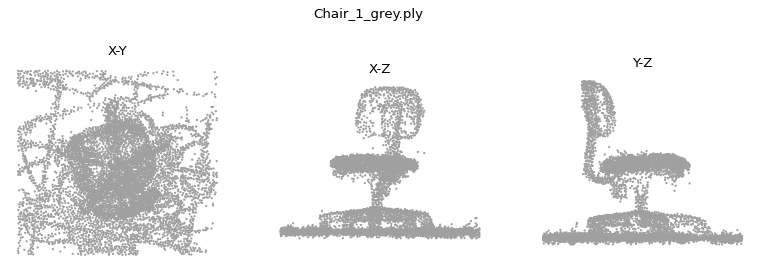

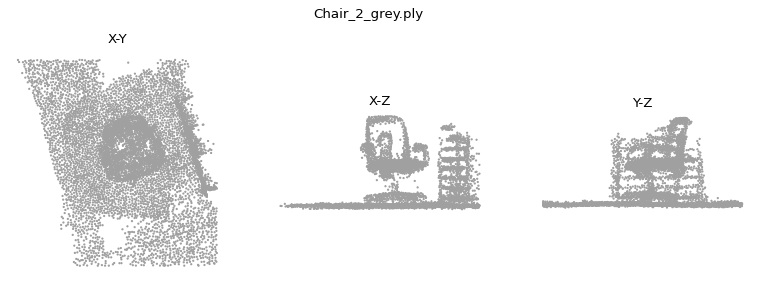

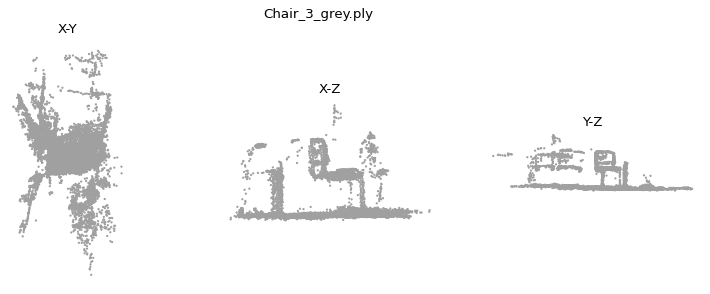

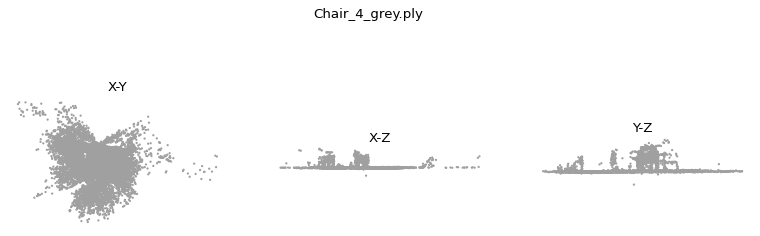

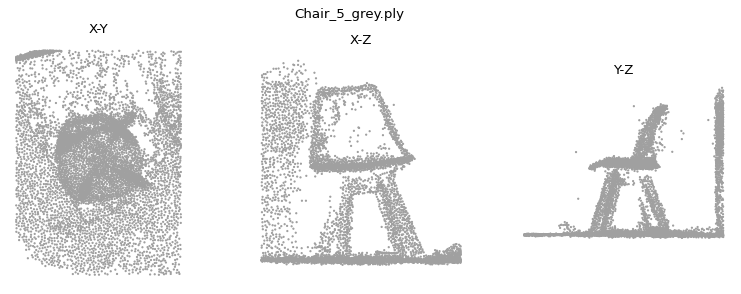

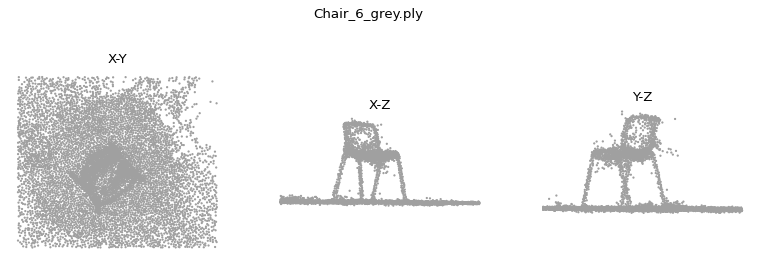

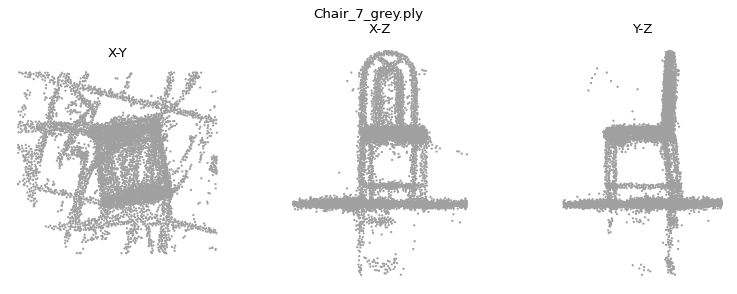

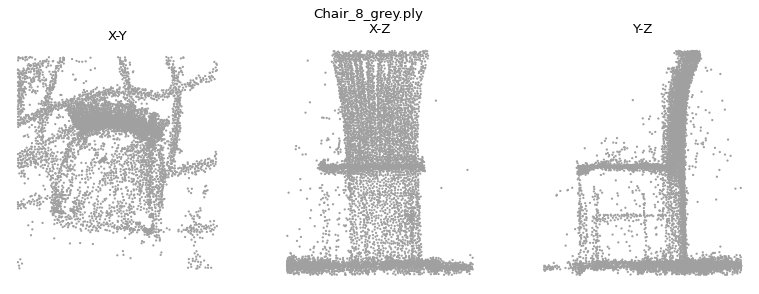

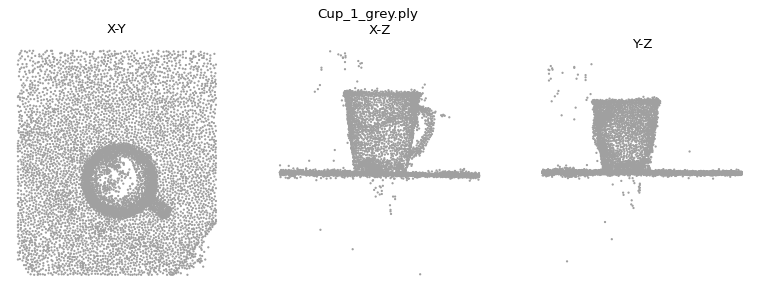

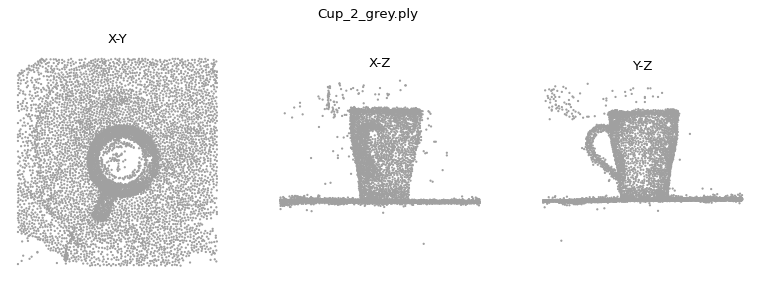

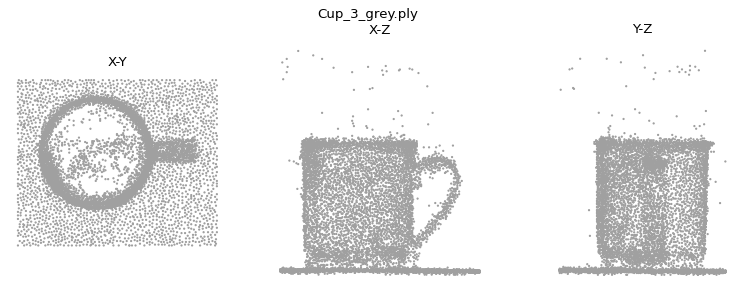

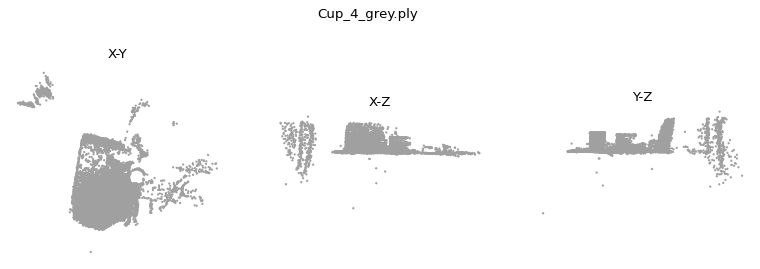

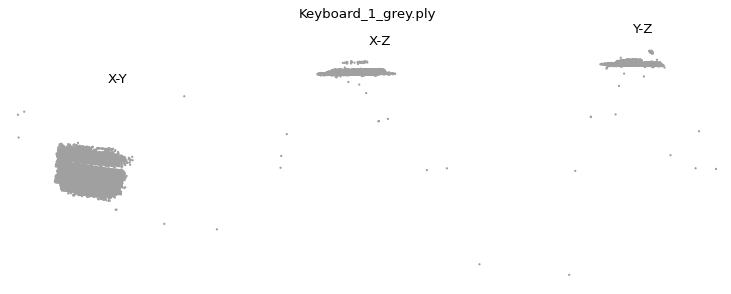

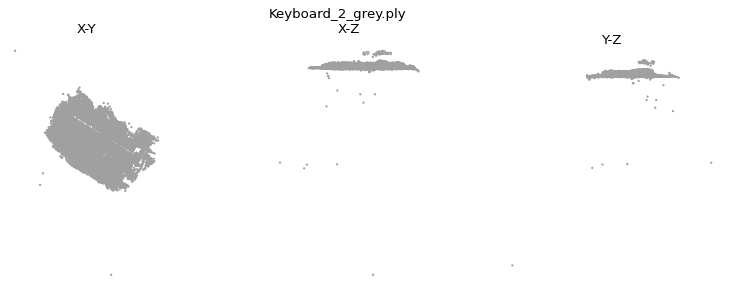

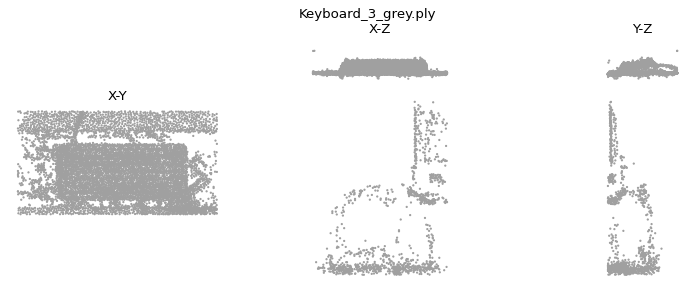

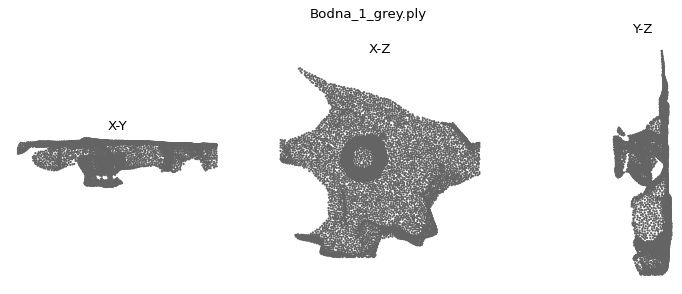

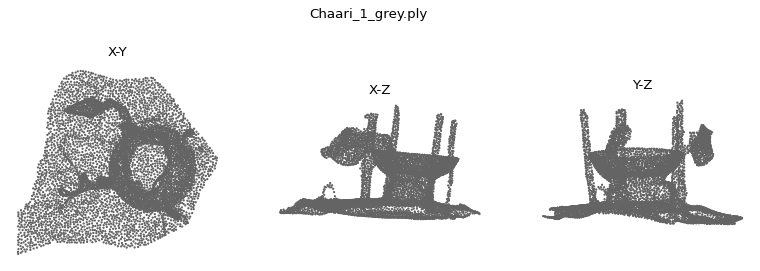

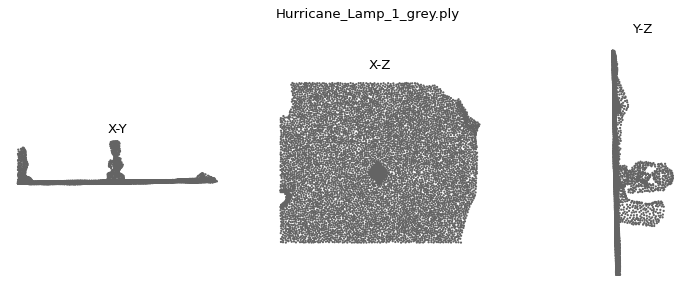

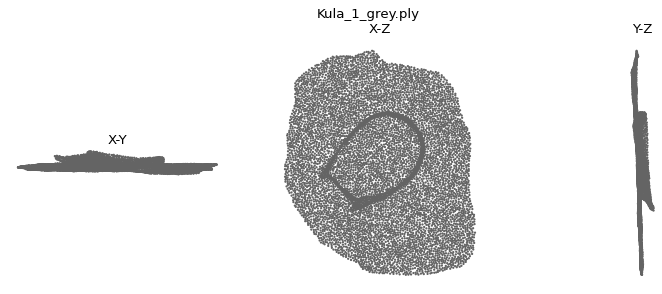

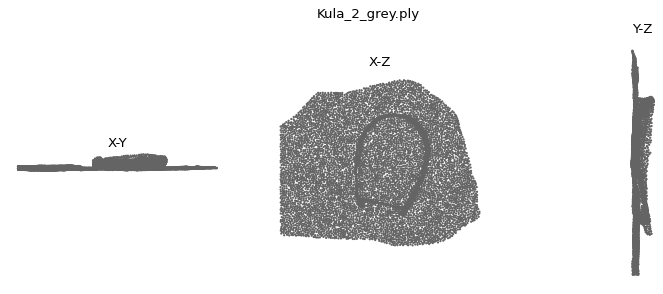

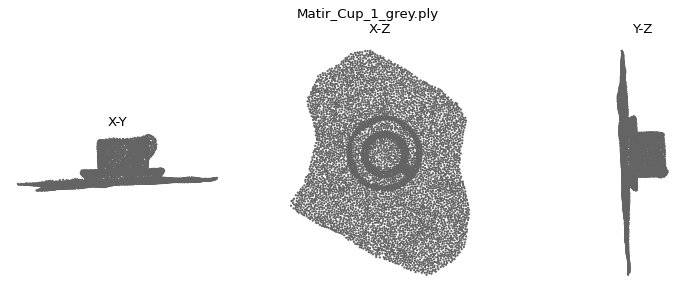

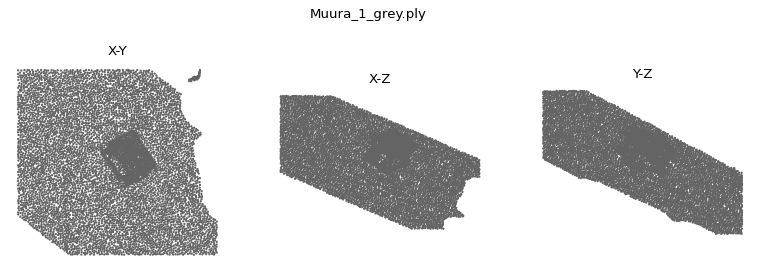

In [ ]:
from IPython.display import display
from pointllm_helpers import preprocess, preview, ROTATIONS, PAPER_PROMPTS

ROTATION = "None"   # options: list(ROTATIONS)

for p in SCANS:
    pts, has_color = preprocess(p, rotation=ROTATION)
    display(preview(pts, title=os.path.basename(p) + ("" if has_color else "  (no colour)")))

---
# Part 3 · Ask PointLLM

## Start the model in the background

This starts `src/pointllm_worker.py` with the venv's Python 3.10. The worker loads the model **once** (the first time it also downloads ~14 GB) and then waits for questions. The helper `ask_pointllm()` sends it a question and waits for the answer.

> 🧠 `subprocess.Popen` starts another program and keeps a "pipe" to it. We write questions into its `stdin` and read answers from its `stdout`, one JSON line each way.

In [ ]:
import json, subprocess

def start_worker():
    env = {**os.environ, "POINTLLM_DIR": POINTLLM_DIR}
    w = subprocess.Popen(["/content/venv/bin/python", "-u", f"{REPO_DIR}/src/pointllm_worker.py"],
                         cwd=POINTLLM_DIR, env=env, text=True, bufsize=1,
                         stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    print("Loading the model (first time: downloads ~14 GB, be patient)...")
    for line in w.stdout:
        if "@@READY@@" in line:
            print("✅ Model ready.")
            return w
        if line.strip():
            print("  ", line.rstrip()[:200])
    raise RuntimeError("The worker stopped while loading. Read the log above.")


def ask_pointllm(path, prompt, rotation="None", sample=False):
    worker.stdin.write(json.dumps({"path": path, "prompt": prompt, "rotation": rotation, "sample": sample}) + "\n")
    worker.stdin.flush()
    for line in worker.stdout:
        if line.startswith("@@RESULT@@"):
            res = json.loads(line[len("@@RESULT@@"):])
            if "error" in res:
                raise RuntimeError(res["error"])
            return res["answer"]
    raise RuntimeError("The worker died. Re-run this cell to restart it.")


if "worker" not in globals() or worker.poll() is not None:  # don't load twice
    worker = start_worker()

Loading the model (first time: downloads ~14 GB, be patient)...
   /content/venv/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
     warnings.warn(
   /content/venv/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possi
     warnings.warn(
   Loading PointBERT config from /content/PointLLM/pointllm/model/pointbert/PointTransformer_8192point_2layer.yaml.
   Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]


RuntimeError: The worker stopped while loading. Read the log above.

## Ask one question

Change `SCAN` and `QUESTION` and re-run this cell as often as you like. The model stays loaded.

The three prompts from the PointLLM paper are in `PAPER_PROMPTS`:
- `"What is this?"`
- `"This is an object of "`: the model completes the sentence
- `"Caption this 3D model in detail."`

In [ ]:
SCAN = SCANS[0]
QUESTION = "What is this?"

print(os.path.basename(SCAN), "|", QUESTION)
print("PointLLM:", ask_pointllm(SCAN, QUESTION, rotation=ROTATION))

## Batch run: every scan × every paper prompt → CSV

This is the cell that produces our **results**. Each row records which object, which capture method, which rotation and prompt, and what PointLLM answered. The CSV goes to `RESULTS_DIR` (on Drive if you used Drive).

`ROTATIONS_TO_TRY` lets us test whether orientation changes the answer.

In [ ]:
import pandas as pd
from datetime import datetime

ROTATIONS_TO_TRY = [ROTATION]          # e.g. ["None", "+90 deg about X"]
PROMPTS_TO_TRY = PAPER_PROMPTS

rows = []
for p in SCANS:
    meta = parse_scan_name(p)
    for rot in ROTATIONS_TO_TRY:
        for q in PROMPTS_TO_TRY:
            ans = ask_pointllm(p, q, rotation=rot)
            rows.append({"file": os.path.basename(p), **meta, "rotation": rot, "prompt": q, "answer": ans})
            print(f"{os.path.basename(p)} | {rot} | {q!r}\n   -> {ans}\n")

results = pd.DataFrame(rows)
out_csv = f"{RESULTS_DIR}/pointllm_{datetime.now():%Y%m%d_%H%M}.csv"
results.to_csv(out_csv, index=False)
print("Saved", out_csv)
results

## (Optional) Free chat about one scan

Type questions. Press **Enter on an empty line** to stop.

In [ ]:
SCAN = SCANS[0]
print("Chatting about", os.path.basename(SCAN))
while True:
    q = input("You > ").strip()
    if not q:
        break
    print("PointLLM:", ask_pointllm(SCAN, q, rotation=ROTATION))

## Stop the model (frees the GPU)

Do this when you're done, or before switching to another model. Colab also frees everything when the runtime disconnects.

In [ ]:
worker.terminate()
print("Worker stopped.")

---
## Troubleshooting

| Problem | Try |
|---|---|
| `CUDA out of memory` | Runtime → Restart session, run again. Make sure no other worker is running. |
| Crash while loading, RAM full | System RAM ran out. Use a High-RAM runtime (Colab Pro) or retry. |
| Answers look random | Look at the preview. Is the object upright and are the background and ground cropped away? Try another `ROTATION`. |
| Worker error mentions an import | PointLLM's API changed. Compare `src/pointllm_helpers.py` with `PointLLM/pointllm/eval/PointLLM_chat.py`. |